# Biweekly Report 2

## Candido Seneriches IV

### Large-Minibatch SGD and Gradual Warmup
For this part of the report, I would like to build upon my previous investigation of Stochastic Gradient Descent (SGD) and focus on how it behaves when training convolutional neural networks. In particular, I will be experimenting with different minibatch sizes, learning rates, and a technique known as gradual warmup. 

Using the Tiny ImageNet dataset, I want to see how changing these parameters affects training time, convergence and model accuracy. I will also be exploring the mathematical reasoning behind linear learning-rate scaling and whether these techniques can make training more efficient without signifcantly affecting performance. I will also take the time to also perform an Exploratory Data Analysis on Tiny Imagenet as a sort-of test run when I will eventually be tackling Imagenet in the future. With all of that said, let's get started.

To begin, let's go over briefly the underlying mathematics behind what this part of the report is doing. Suppose that the training dataset contains $N$ labeled examples. The objective that the model has is to minimize the average loss, defined as

$$
L(\theta) = \frac{1}{N}\sum_{i=1}^{N} \ell(x_i, y_i; \theta)
$$

for
- $\theta$ represents the trainable parameters of the CNN
- $(x_i, y_i)$ represents a training image and its label
- $\ell$ measures the prediction error for an individual example.

Rather than comptuing the gradient over the entire dataset for every update, minibatch SGD estimates it using a subset $\mathcal{B}_t$:

$$
\boxed{\theta_{t + 1} = \theta_t - \eta \frac{1}{B} \sum_{i \in \mathcal{B}_t} \nabla_{\theta}\ell(x_i), y_i; \theta_t}
$$

For $\eta$ is the learning rate, and $B = \left\lvert \mathcal{B}_t \right\rvert$ is the minibatch size. This minibatch size determines how many training examples contribute to each parameter update. For a dataset containing $N$ examples, the number of minibatches per epoch is:

$$
\boxed{S = \left\lceil \frac{N}{B} \right\rceil}
$$

If $B$ is increased, then the number of updates per epoch is reduced, but it also increases the amount of data processed during each update. This introduces a tradeoff between computational efficiency and optimization behavior, which I will investigate through this notebook.

When increasing the minibatch size, one approach is to scale the learning rate proportionally as

$$
\eta(B) = \eta_0 \frac{B}{B_0}
$$

For $B_0$ and $\eta_0$ are the reference minibatch size and learning rate. This is known as the **linear scaling rule**, movtivated by approximating several smaller SGD updates with one larger update, although the approximation is not always valid. To improve stability during the initial stages of training, we can also introduce *gradual warmup*, where the learning rate increases progressively toward its target value rather than starting at that value immediately. Both techniques will be investigated to determine whether or not they improve convergence when training with larger minibatches.

So now with the mathematics established, the questions now to answer are:
- How does minibatch size affect training efficiency?
- How does minibatch size affect the learning process?
- Can linear scaling and warmup improve large-minibatch training?

With all of that established, let's go ahead and officially start by loading up the data.

In [58]:
# General utilities
import os
import time
import math
import random

# Numerical analysis and data visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Dataset preparation
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from PIL import Image

In [59]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")

if device.type == "cuda":
  print(f"GPU: {torch.cuda.get_device_name(0)}")
  print(f"Available GPUs: {torch.cuda.device_count()}")

  gpu_memory = torch.cuda.get_device_properties(0).total_memory
  print(f"GPU Memory: {gpu_memory / (1024 ** 3):.2f} GB")

else:
  print("CUDA unavailable. Running on CPU.")

PyTorch Version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Available GPUs: 2
GPU Memory: 14.56 GB


For the data, we'll be using the Tiny Imagenet dataset, which is a scaled-down subset of the official ImageNet database. Besides investigating any further, I am also taking the time to investigate this dataset and what features it has. All in all, this will be a sort-of dry run for when I do train models on the full ImageNet dataset. As reference, this dataset can be accessed on Kaggle [Here](https://www.kaggle.com/datasets/akash2sharma/tiny-imagenet)

In [60]:
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/akash2sharma/tiny-imagenet/tiny-imagenet-200")

print("Dataset exists:", DATA_DIR.exists())
print("Contents:", [item.name for item in DATA_DIR.iterdir()])

Dataset exists: True
Contents: ['test', 'tiny-imagenet-200', 'train', 'val', 'wnids.txt', 'words.txt']


In [61]:
# Dataset directories
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Metadata files
WNIDS_FILE = DATA_DIR / "wnids.txt"
WORDS_FILE = DATA_DIR / "words.txt"
VAL_ANNOTATIONS = VAL_DIR / "val_annotations.txt"

# Load class identifiers
with open(WNIDS_FILE, "r") as f:
  class_ids = [line.strip() for line in f if line.strip()]

# Map class identifiers to numerical labels
class_to_idx = {
  class_id: idx for idx, class_id in enumerate(class_ids)
}

# Load readable class descriptions
class_descriptions = {}

with open(WORDS_FILE, "r") as f:
  for line in f:
    parts = line.strip().split("\t", 1)

    if len(parts) == 2:
      class_descriptions[parts[0]] = parts[1].split(",")[0]

# Match readable names to class indices
class_names = [
  class_descriptions.get(class_id, class_id)
  for class_id in class_ids
]

# Verify dataset paths and metadata
required_paths = [
  TRAIN_DIR,
  VAL_DIR,
  WNIDS_FILE,
  WORDS_FILE,
  VAL_ANNOTATIONS
]

paths_valid = all(path.exists() for path in required_paths)
classes_valid = len(class_ids) == len(class_to_idx) == len(class_names) == 200
labels_valid = all(name.strip() for name in class_names)

if paths_valid and classes_valid and labels_valid:
  print("Tiny ImageNet setup: PASSED")
  print(f"Classes loaded: {len(class_ids)}")
  print("Training and validation paths: Ready")
  print("Class labels: Ready")
else:
  print("Tiny ImageNet setup: FAILED")
  print("Missing paths:", [str(path) for path in required_paths if not path.exists()])
  print("Class metadata valid:", classes_valid and labels_valid)

Tiny ImageNet setup: PASSED
Classes loaded: 200
Training and validation paths: Ready
Class labels: Ready


Going a bit deeper into tiny Imagenet, this dataset contains 200 image classes, with images resized to $64 \times 64$ pixels. This EDA will focus on verifying the dataset, examining its class distribution, visualizing sample images, and investigating how different minibatch sizes affect the composition of training data. These observations will help establish the context for the experiments involving batch size, optimization, and computational efficiency.

In [62]:
# Collect training image paths and labels
train_records = []

for class_id in class_ids:
  image_dir = TRAIN_DIR / class_id / "images"

  for image_path in image_dir.glob("*.JPEG"):
    train_records.append((image_path, class_to_idx[class_id]))

# Read validation annotations
val_records = []

with open(VAL_ANNOTATIONS, "r") as f:
  for line in f:
    filename, class_id, *_ = line.strip().split("\t")

    image_path = VAL_DIR / "images" / filename
    val_records.append((image_path, class_to_idx[class_id]))

# Verify image counts and class coverage
train_labels = np.array([label for _, label in train_records])
val_labels = np.array([label for _, label in val_records])

print(f"Training images: {len(train_records):,}")
print(f"Validation images: {len(val_records):,}")
print(f"Classes represented: {len(np.unique(train_labels))}")
print(f"Training images per class: {np.bincount(train_labels).min()}–{np.bincount(train_labels).max()}")

Training images: 100,000
Validation images: 10,000
Classes represented: 200
Training images per class: 500–500


In [63]:
# Inspect a sample of training images
rng = np.random.default_rng(SEED)

sample_indices = rng.choice(len(train_records), size=100, replace=False)

image_sizes = []
image_modes = set()

for idx in sample_indices:
  image_path, _ = train_records[idx]

  with Image.open(image_path) as image:
    image_sizes.append(image.size)
    image_modes.add(image.mode)

print(f"Image dimensions: {set(image_sizes)}")
print(f"Image color modes: {sorted(image_modes)}")
print(f"Sample size: {len(sample_indices)}")

Image dimensions: {(64, 64)}
Image color modes: ['L', 'RGB']
Sample size: 100


Here, the dataset already contains 100,000 training images and 10,000 validation images distributed across class. For each class, they contain 500 training images, confirming that the training dataset is balanced.

A random sample of 100 images also confirmed the expected $64 \times 64$ resolution. Both RGB and grayscale images were encounted, so all images will be converted to RGB during preprocessing to ensure consistent input dimensions for the CNN.

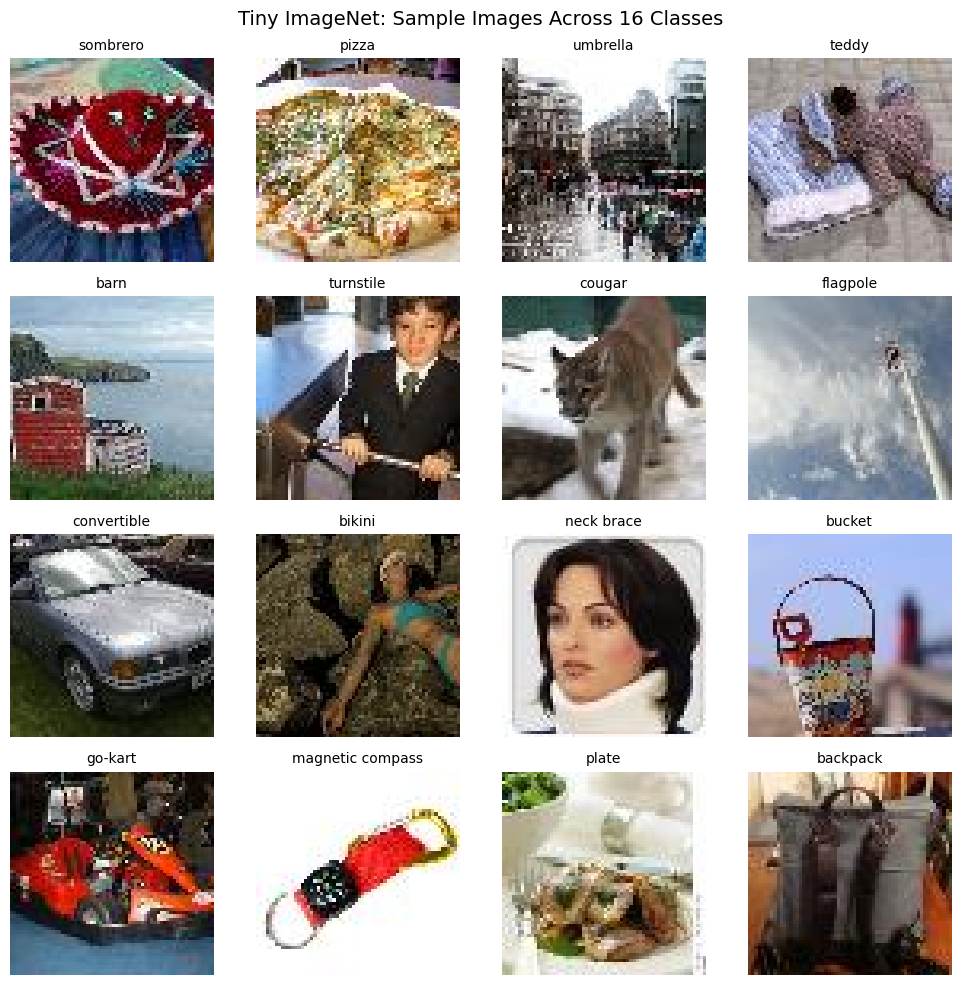

In [64]:
# Select 16 different classes
rng = np.random.default_rng(SEED)

selected_classes = rng.choice(len(class_ids), size=16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for ax, class_idx in zip(axes.flat, selected_classes):
  # Find images belonging to the selected class
  class_indices = np.where(train_labels == class_idx)[0]
  image_idx = rng.choice(class_indices)

  image_path, label = train_records[image_idx]

  # Load and display the image
  with Image.open(image_path) as image:
    image = image.convert("RGB")
    ax.imshow(image)

  ax.set_title(class_names[label], fontsize=10)
  ax.axis("off")

plt.suptitle("Tiny ImageNet: Sample Images Across 16 Classes", fontsize=14)
plt.tight_layout()
plt.show()

Here in this picture gallery, this illustrates the diversity of objects represented in Tiny ImageNet, ranging from animals and vehicles to everydat objects. Images also vary in their backgrounds, object positions, and visual complexity.

Despite the relatively small image resolution, the CNN must learn to distinguish among 200 classes, including categories that may share similar visual features. Therefore this makes tiny ImageNet a more challenging classification task than say CIFAR-10 and provides a useful setting for investigating large-minibatch SGD.

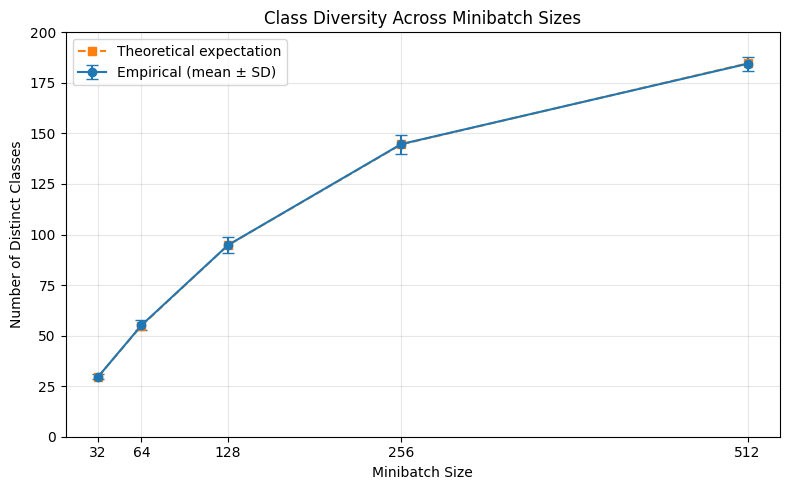

In [65]:
# Investigate class diversity across minibatch sizes
batch_sizes = [32, 64, 128, 256, 512]
num_trials = 100

rng = np.random.default_rng(SEED)

average_classes = []
std_classes = []

for batch_size in batch_sizes:
  distinct_counts = []

  for _ in range(num_trials):
    batch_labels = rng.choice(
      train_labels,
      size=batch_size,
      replace=False
    )

    distinct_counts.append(len(np.unique(batch_labels)))

  average_classes.append(np.mean(distinct_counts))
  std_classes.append(np.std(distinct_counts))

# Theoretical expectation under independent uniform sampling
expected_classes = [
  len(class_ids) * (1 - (1 - 1 / len(class_ids)) ** batch_size)
  for batch_size in batch_sizes
]

plt.figure(figsize=(8, 5))

plt.errorbar(
  batch_sizes,
  average_classes,
  yerr=std_classes,
  marker="o",
  capsize=4,
  label="Empirical (mean ± SD)"
)

plt.plot(
  batch_sizes,
  expected_classes,
  marker="s",
  linestyle="--",
  label="Theoretical expectation"
)

plt.title("Class Diversity Across Minibatch Sizes")
plt.xlabel("Minibatch Size")
plt.ylabel("Number of Distinct Classes")
plt.xticks(batch_sizes)
plt.ylim(0, 200)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

The final thing to consider in this EDA is the minibatch composition. The following experiment examines how increasing minibatch size affects the number of distinct classes represented in a randomly sampled group of training images.

As minibatch size increases, more classes tend to appear within each batch, although the increase gradually slows because the dataset contains a fixed number of classes. The empirical results can also be compared with the theoretical expectation under uniform sampling. 

This provides an initial perspective on how minibatch size changes the composition of data used for each SGD update. However, class diversity alone doesn't determine the quality of the gradient estimate, so the effects on convergence and training efficiency will be investigated through the CNN experiments.

Moving onto the CNN itself, it will consist of three convolutional block, with each block applying a $3 \times 3$ convolution, batch normalization, ReLU activation, and max pooling. The number of feature channels increases from 32 to 64 and finally 126 as the spatial dimensions decrease.

After the convolutional blocks, global average pooling reduces the feature maps to a feature vector, which is passed into a fully connected layer producing 200 class scores.

The architecture will remain fixed throughout our experiments so that the differences in training performance can be attributed primarily to the minibatch size and learning-rate strategies rather than changes in network structure.

In [66]:
class TinyImageNetCNN(nn.Module):
  def __init__(self):
    super().__init__()

    self.features = nn.Sequential(
      # Block 1: 3 x 64 x 64 -> 32 x 32 x 32
      nn.Conv2d(3, 32, kernel_size=3, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      # Block 2: 32 x 32 x 32 -> 64 x 16 x 16
      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      # Block 3: 64 x 16 x 16 -> 128 x 8 x 8
      nn.Conv2d(64, 128, kernel_size=3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2)
    )

    self.classifier = nn.Sequential(
      nn.AdaptiveAvgPool2d((1, 1)),
      nn.Flatten(),
      nn.Linear(128, 200)
    )

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

Mathematically, each convolutional block applies four operations: convolution, batch normalization, ReLU activation, and max pooling. Mathematically, this can be represented as

$$
X_{\ell+1}=\operatorname{MaxPool}\left(\operatorname{ReLU}\left(\operatorname{BN}\left(W_\ell*X_\ell+b_\ell\right)\right)\right)
$$

where $W_\ell*X_\ell$ represents convolution, $\operatorname{BN}$ normalizes the intermediate activations, ReLU introduces nonlinearity, and max pooling reduces the spatial dimensions while retaining prominent features.

After three convolutional blocks, global average pooling reduces the resulting feature maps into a vector of 128 features. The final fully connected layer computes

$$
z=W_{\mathrm{out}}h+b_{\mathrm{out}},\qquad z\in\mathbb{R}^{200}
$$

where $h\in\mathbb{R}^{128}$ is the extracted feature vector and $z$ contains the 200 class logits used for classification.

He initialization is applied to the convolutional and linear layers to help maintain stable activation magnitudes throughout the network. The architecture remains fixed across experiments to isolate the effects of minibatch size and learning-rate strategies.

In [67]:
# Initialize CNN weights
def initialize_model(model):
  for module in model.modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
      nn.init.kaiming_normal_(
        module.weight,
        mode="fan_in",
        nonlinearity="relu"
      )

      if module.bias is not None:
        nn.init.zeros_(module.bias)

# Construct the model
torch.manual_seed(SEED)

model = TinyImageNetCNN()
initialize_model(model)
model = model.to(device)

# Verify output dimensions
with torch.no_grad():
  sample_input = torch.randn(2, 3, 64, 64, device=device)
  sample_output = model(sample_input)

parameter_count = sum(
  p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Device: {device}")
print(f"Input shape: {tuple(sample_input.shape)}")
print(f"Output shape: {tuple(sample_output.shape)}")
print(f"Trainable parameters: {parameter_count:,}")

Device: cuda
Input shape: (2, 3, 64, 64)
Output shape: (2, 200)
Trainable parameters: 119,496


Now that the CNN architecture is built and verified, let's prepare the images for training, and for the following experiments, the preprocessing of the data must be consistent across all minibatch experiments.

In terms of the images, the CNN expects input tensors of the shape

$$
(B, 3, 64, 64)
$$

For $B$ is the minibatch size. For this, three three transformations will be made:
- RGB Conversion
- Tensor conversion (Converting pixel intesities from integers to floating-point values)
- Normalization

In [68]:
# Image preprocessing
image_transform = transforms.Compose([
  transforms.Lambda(lambda image: image.convert("RGB")),
  transforms.ToTensor(),
  transforms.Normalize(
    mean=(0.485, 0.456, 0.406),
    std=(0.229, 0.224, 0.225)
  )
])

In [69]:
class TinyImageNetDataset(Dataset):
  def __init__(self, records, transform=None):
    self.records = records
    self.transform = transform

  def __len__(self):
    return len(self.records)

  def __getitem__(self, idx):
    image_path, label = self.records[idx]

    with Image.open(image_path) as image:
      image = image.convert("RGB")

      if self.transform is not None:
        image = self.transform(image)

    return image, label


train_dataset = TinyImageNetDataset(
  train_records,
  transform=image_transform
)

val_dataset = TinyImageNetDataset(
  val_records,
  transform=image_transform
)

print(f"Training samples: {len(train_dataset):,}")
print(f"Validation samples: {len(val_dataset):,}")

Training samples: 100,000
Validation samples: 10,000


Verify the dataset returns the correctly shaped tensors and numerical labels

In [70]:
sample_image, sample_label = train_dataset[0]

print(f"Image shape: {tuple(sample_image.shape)}")
print(f"Image dtype: {sample_image.dtype}")
print(f"Training samples: {len(train_dataset):,}")
print(f"Validation samples: {len(val_dataset):,}")

Image shape: (3, 64, 64)
Image dtype: torch.float32
Training samples: 100,000
Validation samples: 10,000


Now that the images have been preprocessed, I'll use PyTorch's `DataLoader` to organize them into minibatches for training and validation. A `DataLoader` helps group the images into batches, shuffle training examples, and load images efficiently.

For the experiments, the batch size $B$ will be configurable, allowing me to investigate its effect on training performance without changing the CNN architecture. With $N = 100,000$ training images, the number of minibatches per epoch is

$$
S(B) = \left\lceil \frac{N}{B} \right\rceil
$$

with each minibatch generally corresponding to one SGD parameter update.

In [71]:
def create_dataloaders(batch_size, seed=42):
  generator = torch.Generator().manual_seed(seed)

  train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    generator=generator
  )

  val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
  )

  return train_loader, val_loader

To verify that this data loader function works, let's test it with a batch size of 128.

In [72]:
BATCH_SIZE = 128

train_loader, val_loader = create_dataloaders(BATCH_SIZE, seed=SEED)

images, labels = next(iter(train_loader))

print(f"Batch size: {BATCH_SIZE}")
print(f"Image batch shape: {tuple(images.shape)}")
print(f"Label batch shape: {tuple(labels.shape)}")
print(f"Training batches per epoch: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Batch size: 128
Image batch shape: (128, 3, 64, 64)
Label batch shape: (128,)
Training batches per epoch: 782
Validation batches: 79


And finally, let's see how increasing batch size reduces the number of SGD updates per epoch.

In [ ]:
# Compare minibatch sizes and SGD updates
batch_sizes = [32, 64, 128, 256, 512]

batch_summary = pd.DataFrame({
  "Batch Size": batch_sizes,
  "SGD Updates per Epoch": [
    (len(train_dataset) + B - 1) // B
    for B in batch_sizes
  ]
})

display(batch_summary)

,Batch Size,SGD Updates per Epoch
0,32,3125
1,64,1563
2,128,782
3,256,391
4,512,196


Here, the table demonstrates the inverse relationship between minibatch size and the number of SGD updates performed per epoch. As the batch size increases, fewer updates are required to process the entire training dataset.

However, fewer updates do not necessarily translate into proportionally faster training, since larger minibatches require more computation per update. This motivates our upcoming experiments, where we will compare actual training times and model performance across different batch sizes.

The final part of setup is setting up two functions, one function will perform one complete training epoch, processing every minibatch and updating the CNN's parameters using SGD.

For each minitbatch $\mathcal{B}_t$, the optimizer applies

$$
w_{t + 1} = w_t - \eta_t \frac{1}{| \mathcal{B}_t |} \sum_{i \in \mathcal{B}_t} \nabla_{w}\ell_{i}(w_t)
$$

Where $\eta_t$ is the learning rate and $w_t$ represents the CNN's trainable parameters.

The other function will be a validation function, in which it will evaluate the CNN without modifying the parameters. For both functions, they'll return the same metrics:

$$
\text{Average Loss} = \frac{1}{N} \sum_{i = 1}{N} \ell_i
$$

$$
\text{Accuracy} = \frac{\text{Correct Predictions}}{N}
$$

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
  model.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for images, labels in loader:
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    batch_size = labels.size(0)

    total_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

  return total_loss / total, correct / total

def evaluate(model, loader, criterion, device):
  model.eval()

  total_loss = 0.0
  correct = 0
  total = 0

  with torch.inference_mode():
    for images, labels in loader:
      images = images.to(device, non_blocking=True)
      labels = labels.to(device, non_blocking=True)

      outputs = model(images)
      loss = criterion(outputs, labels)

      batch_size = labels.size(0)

      total_loss += loss.item() * batch_size
      correct += (outputs.argmax(dim=1) == labels).sum().item()
      total += batch_size

  return total_loss / total, correct / total